In [42]:
import matplotlib
import numpy as np
from scipy.spatial import KDTree
from sklearn.cluster import DBSCAN
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from sklearn.neighbors import NearestNeighbors


In [43]:
def show_cloud(points_plt):
    ax = plt.axes(projection='3d')
    ax.scatter(points_plt[:,0], points_plt[:,1], points_plt[:,2], s=0.01)
    plt.show()

def show_scatter(x,y):
    plt.scatter(x, y)
    plt.show()

def get_ground_level(pcd):
    z = pcd[:, 2]
    num_bins = int(np.ceil((z.max() - z.min()) / 0.3))
    counts, edges = np.histogram(z, bins=num_bins)
    peak_index = np.argmax(counts)
    ground_level = (edges[peak_index] + edges[peak_index + 1]) / 2.0
    return ground_level, counts, edges

In [44]:
pcd = np.load("dataset1.npy")


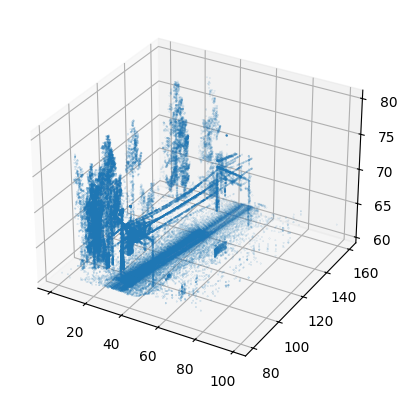

In [45]:
show_cloud(pcd)


## Task 1 (3)
find the best value for the ground level
One way to do it is useing a histogram 
np.histogram

update the function get_ground_level() with your changes

For both the datasets
Report the ground level in the readme file in your github project
Add the histogram plots to your project readme

In [46]:
est_ground_level, counts, edges = get_ground_level(pcd)
print(est_ground_level)

61.32764843750003


In [47]:
centers = (edges[:-1] + edges[1:]) / 2

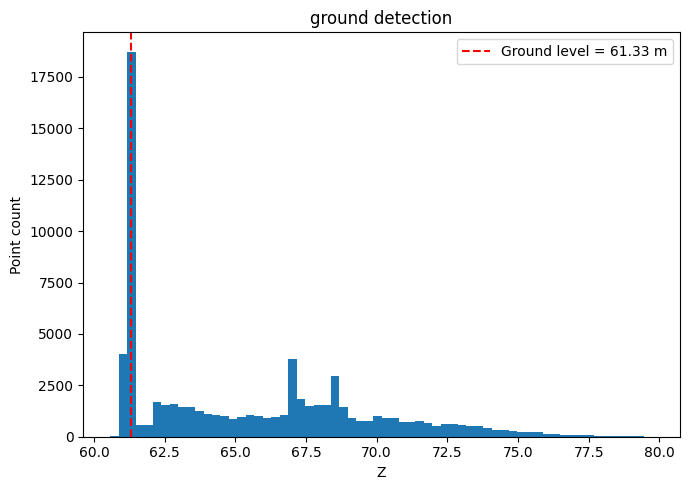

In [48]:
plt.figure(figsize=(7, 5))
plt.bar(centers, counts, width=0.3)
plt.axvline(est_ground_level, color='red', linestyle='--', label=f'Ground level = {est_ground_level:.2f} m')
plt.xlabel('Z')
plt.ylabel('Point count')
plt.title('ground detection')
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
pcd_above_ground = pcd[pcd[:,2] > est_ground_level] 

In [73]:
pcd_above_ground.shape

(55490, 3)

In [74]:
print(pcd_above_ground[:,2].min())

61.32800000000003


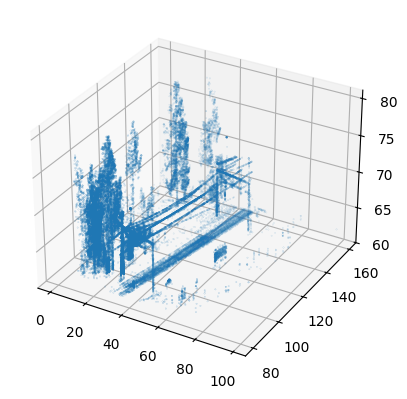

In [75]:
#side view
show_cloud(pcd_above_ground)

## Task 2 (+1)

Find an optimized value for eps.
Plot the elbow and extract the optimal value from the plot
Apply DBSCAN again with the new eps value and confirm visually that clusters are proper

https://www.analyticsvidhya.com/blog/2020/09/how-dbscan-clustering-works/
https://machinelearningknowledge.ai/tutorial-for-dbscan-clustering-in-python-sklearn/

For both the datasets
Report the optimal value of eps in the Readme to your github project
Add the elbow plots to your github project Readme
Add the cluster plots to your github project Readme

In [52]:

k = 5
nbrs = NearestNeighbors(n_neighbors=k).fit(pcd_above_ground)
distances, _ = nbrs.kneighbors(pcd_above_ground)
k_distances = np.sort(distances[:, k - 1])

x = np.arange(len(k_distances))
y = k_distances
p1, p2 = np.array([x[0], y[0]]), np.array([x[-1], y[-1]])
line_vec = (p2 - p1) / np.linalg.norm(p2 - p1)
vecs = np.stack([x - p1[0], y - p1[1]], axis=1)
proj = np.outer(vecs @ line_vec, line_vec)
dist_to_line = np.linalg.norm(vecs - proj, axis=1)
elbow_idx = np.argmax(dist_to_line)
optimal_eps = k_distances[elbow_idx]

In [53]:
print(optimal_eps)

0.9399207417966629


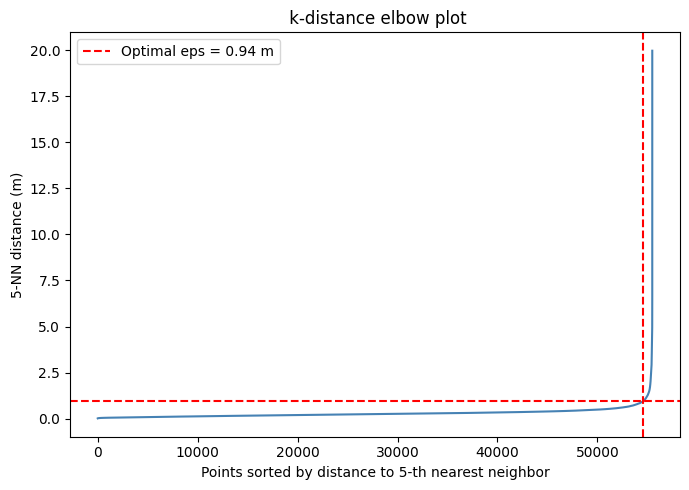

In [54]:
plt.figure(figsize=(7, 5))
plt.plot(x, y, color='steelblue')
plt.axhline(optimal_eps, color='red', linestyle='--',
            label=f'Optimal eps = {optimal_eps:.2f} m')
plt.axvline(elbow_idx, color='red', linestyle='--')
plt.xlabel(f'Points sorted by distance to {k}-th nearest neighbor')
plt.ylabel(f'{k}-NN distance (m)')
plt.title(' k-distance elbow plot')
plt.legend()
plt.tight_layout()
plt.show()

In [55]:
clustering = DBSCAN(eps=optimal_eps, min_samples=5).fit(pcd_above_ground)

clusters = len(set(clustering.labels_)) - (1 if -1 in clustering.labels_ else 0)
print(f"Number of clusters: {clusters}")

Number of clusters: 110


In [ ]:
labels = clustering.labels_
noise_mask = labels == -1
unique_clusters = sorted(set(labels[~noise_mask]))

cmap = plt.cm.get_cmap('gist_ncar', len(unique_clusters))
label_to_color = {lbl: cmap(i) for i, lbl in enumerate(unique_clusters)}
point_colors = [label_to_color[lbl] for lbl in labels[~noise_mask]]


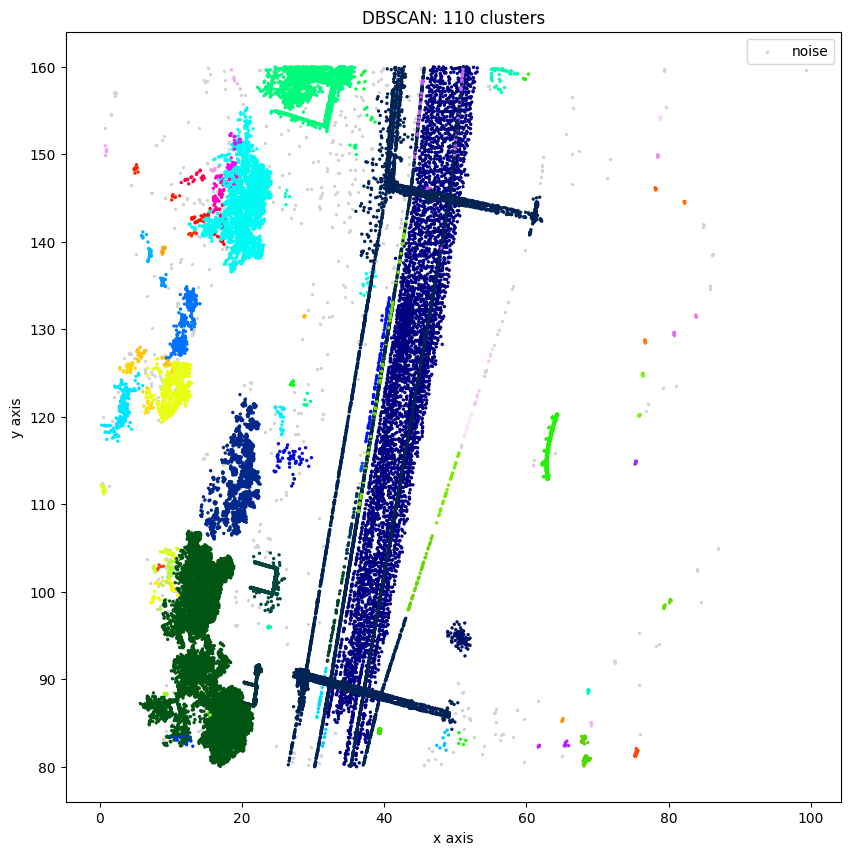

In [70]:

plt.figure(figsize=(10,10))
plt.scatter(pcd_above_ground[noise_mask, 0], pcd_above_ground[noise_mask, 1],
            c='lightgray', s=2, label='noise')
plt.scatter(pcd_above_ground[~noise_mask, 0], pcd_above_ground[~noise_mask, 1],
            c=point_colors, s=2)
plt.title(f'DBSCAN: {clusters} clusters')
plt.xlabel('x axis')
plt.ylabel('y axis')
plt.legend()
plt.show()

With 110 clusters, the default color mapping made things confusing. Matplotlib was normalizing the cluster labels between min and max and picking colors along a gradient, so a lot of clusters ended up looking almost the same color even though they were completely separate in space. It made the plot look like there were way fewer clusters than there actually were.

I fixed it by manually mapping each cluster label to its own color from a colormap (gist_ncar) instead of letting matplotlib normalize them. Once I did that, each cluster showed up as its own distinct color and it was much easier to visually confirm the clustering actually made sense.

## Task 3 (+1)

Find the largest cluster, since that should be the catenary, 
beware of the noise cluster.

Use the x,y span for the clusters to find the largest cluster

For both the datasets
Report min(x), min(y), max(x), max(y) for the catenary cluster in the Readme of your github project
Add the plot of the catenary cluster to the readme

In [ ]:
unique_labels = [lbl for lbl in set(labels) if lbl != -1]

spans = {}
for lbl in unique_labels:
    mask = labels == lbl
    pts = pcd_above_ground[mask]
    x_min, x_max = pts[:, 0].min(), pts[:, 0].max()
    y_min, y_max = pts[:, 1].min(), pts[:, 1].max()
    area = (x_max - x_min) * (y_max - y_min)
    spans[lbl] = (x_min, y_min, x_max, y_max, area)

catenary_label = max(spans, key=lambda lbl: spans[lbl][4])
x_min, y_min, x_max, y_max, area = spans[catenary_label]

print(f"Catenary cluster label: {catenary_label}")
print(f"min(x)={x_min:.2f}, min(y)={y_min:.2f}, max(x)={x_max:.2f}, max(y)={y_max:.2f}")

Catenary cluster label: 2
min(x)=26.50, min(y)=80.02, max(x)=62.14, max(y)=159.99


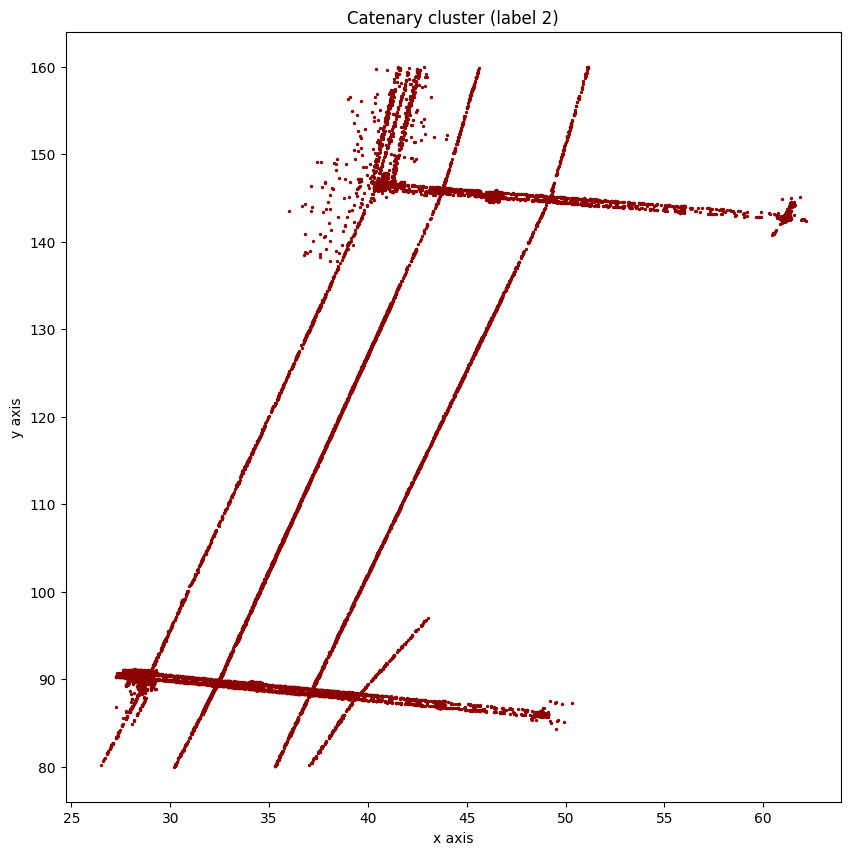

In [61]:
catenary_mask = labels == catenary_label
plt.figure(figsize=(10,10))
plt.scatter(pcd_above_ground[catenary_mask, 0], pcd_above_ground[catenary_mask, 1], s=2, color='darkred')
plt.title(f'Catenary cluster (label {catenary_label})')
plt.xlabel('x axis')
plt.ylabel('y axis')
plt.show()